# Evaluasi Kraken BLLA Base (Hugging Face) — Segmentasi **Baris (Line)**

Notebook ini **hanya fokus pada line segmentation** (TextLine). Region segmentation (TextRegion) tidak dievaluasi.

Alur notebook (anti-bentrok versi paket):
1. Kraken dipasang di **virtual environment terpisah** (`/tmp/kraken_env`), jadi tidak menyentuh paket bawaan Kaggle (transformers, safetensors, torch, dll.).
2. Segmentasi dijalankan lewat *subprocess* di environment itu → hasil prediksi (hanya baris) disimpan ke JSON.
3. Metrik dihitung di kernel utama: **IoU, Precision, Recall, F1, mAP, mAP.50, mAP.50:95** untuk level `line`.
   - Precision/Recall/F1/mAP = rata-rata di seluruh ambang IoU 0.05:0.95.
   - `mAP.50` = AP pada IoU 0.50, `mAP.50:95` = rata-rata AP pada IoU 0.50:0.95 (gaya COCO).
4. Model hasil finetune (`.safetensors`) dipasang ke model kraken lalu dibandingkan dengan model base.

**Tidak perlu restart session.** Aktifkan *Internet* (Settings → Internet On). GPU opsional.

## 0. Dependensi ringan untuk kernel utama
Hanya paket yang tidak bentrok dengan Kaggle. Kraken sendiri dipasang di venv terpisah (bagian 3).

In [3]:
!pip install -q shapely lxml tqdm huggingface_hub

## 1. KONFIGURASI DATASET  (⬅ ISI BAGIAN INI)

In [4]:
import numpy as np, os

# ================== ISI BAGIAN INI ==================
DATASET_ROOT = "/kaggle/input/datasets/gracians/greek-dataset-baseline/test"     # <-- folder utama dataset di Kaggle
IMAGES_DIR   = f"{DATASET_ROOT}/images"              # <-- folder berisi gambar halaman (boleh subfolder)
XML_DIR      = f"{DATASET_ROOT}/xml"                 # <-- folder berisi PAGE XML ground truth (boleh subfolder)

IMAGE_EXTS   = (".jpg", ".jpeg", ".png", ".tif", ".tiff", ".bmp")
# Nama file gambar & XML dipasangkan lewat nama dasar (stem), mis. page_001.jpg <-> page_001.xml

LEVELS       = ["line"]             # hanya evaluasi line segmentation (TextLine)
MAX_PAGES    = None                 # None = semua halaman; isi angka (mis. 20) untuk uji cepat
# ====================================================

# >>>>>> [TAMBAHAN Sauvola–Niblack] — lokasi gambar uji hasil preprocessing (khusus model Finetune SN)
SN_EVAL_DIR = "/kaggle/working/test_sn/images"
# <<<<<< [/TAMBAHAN]

# ---- Pengaturan model (biasanya tidak perlu diubah) ----
HF_REPO_ID   = "small-models-for-glam/kraken-blla-base"
HF_FILENAME  = "blla.mlmodel"

# ---- Pengaturan evaluasi ----
IOU_THRESHOLDS = np.round(np.arange(0.05, 0.96, 0.05), 2)   # 0.05:0.05:0.95 -> dipakai untuk P/R/F1/mAP (tanpa basis 0.5)
MAP50_THR      = 0.50                                       # khusus untuk metrik "mAP.50"
MAP5095_RANGE  = (0.50, 0.95)                               # khusus untuk metrik "mAP.50:95"
assert any(np.isclose(IOU_THRESHOLDS, MAP50_THR)), "IOU_THRESHOLDS harus memuat 0.50"
WORK_DIR       = "/kaggle/working"

# ---- Environment terpisah untuk kraken ----
VENV_DIR           = "/tmp/kraken_env"                      # di /tmp agar tidak ikut tersimpan sebagai output
REUSE_PREDICTIONS  = True                                   # pakai ulang predictions_raw.json bila sudah ada & lengkap
PRED_JSON          = f"{WORK_DIR}/predictions_raw.json"

# Bantuan: lihat isi /kaggle/input untuk menemukan path dataset
for p in sorted(os.listdir("/kaggle/input")) if os.path.exists("/kaggle/input") else []:
    print("/kaggle/input/" + p)

/kaggle/input/datasets
/kaggle/input/notebooks


## 2. Unduh pretrained model dari Hugging Face

In [5]:
from huggingface_hub import hf_hub_download

model_path = hf_hub_download(repo_id=HF_REPO_ID, filename=HF_FILENAME, local_dir=f"{WORK_DIR}/kraken-blla-base")
print("Model tersimpan di:", model_path)
# (Warning "unauthenticated requests to the HF Hub" aman diabaikan.)

blla.mlmodel: reconstructing file:   0%|          |  0.00B / 5.05MB            

blla.mlmodel: downloading bytes:           |  0.00B            

Model tersimpan di: /kaggle/working/kraken-blla-base/blla.mlmodel


## 3. Ground truth (PAGE XML) & pasangan gambar–XML

In [6]:
import glob
from lxml import etree
from PIL import Image
from shapely.geometry import Polygon
from shapely.ops import unary_union

def ltag(e):
    return e.tag.split("}")[-1] if isinstance(e.tag, str) else ""

def parse_points(s):
    pts = []
    for tok in s.strip().split():
        x, y = tok.split(",")[:2]
        pts.append((float(x), float(y)))
    return pts

def to_poly(pts):
    pts = [(float(x), float(y)) for x, y in pts]
    if len(pts) < 3:
        return None
    p = Polygon(pts)
    if not p.is_valid:
        p = p.buffer(0)
    if p.is_empty or p.area <= 0:
        return None
    return p

def child_coords(elem):
    for c in elem:
        if ltag(c) == "Coords":
            return c.get("points")
    return None

def load_gt(xml_path, img_size):
    # Return {"line": [Polygon...]} dalam koordinat piksel gambar asli (hanya TextLine; TextRegion diabaikan).
    root = etree.parse(xml_path).getroot()
    sx = sy = 1.0
    for e in root.iter():
        if ltag(e) == "Page":
            w, h = e.get("imageWidth"), e.get("imageHeight")
            if w and h and float(w) > 0 and float(h) > 0:
                sx, sy = img_size[0] / float(w), img_size[1] / float(h)
            break
    out = {"line": []}
    for e in root.iter():
        if ltag(e) == "TextLine":
            pts = child_coords(e)
            if not pts:
                continue
            poly = to_poly([(x * sx, y * sy) for x, y in parse_points(pts)])
            if poly is not None:
                out["line"].append(poly)
    return out

def index_files(folder, exts):
    d = {}
    for p in glob.glob(os.path.join(folder, "**", "*"), recursive=True):
        if os.path.isfile(p) and p.lower().endswith(exts):
            d[os.path.splitext(os.path.basename(p))[0]] = p
    return d

imgs = index_files(IMAGES_DIR, IMAGE_EXTS)
xmls = index_files(XML_DIR, (".xml",))
pairs = [(k, imgs[k], xmls[k]) for k in sorted(imgs) if k in xmls]
print(f"Gambar: {len(imgs)} | XML: {len(xmls)} | Berpasangan: {len(pairs)}")
if len(pairs) == 0:
    raise SystemExit("Tidak ada pasangan gambar-XML. Periksa IMAGES_DIR / XML_DIR dan kesamaan nama file.")
if MAX_PAGES:
    pairs = pairs[:MAX_PAGES]

Gambar: 27 | XML: 27 | Berpasangan: 27


## 3b. Preprocessing Sauvola–Niblack untuk model Finetune SN  (⬅ TAMBAHAN)

Model **Finetune All (Savuola-Niblack)** dilatih pada citra terbinarisasi, sehingga saat evaluasi gambar uji harus diproses dengan cara yang sama. Sebelumnya notebook ini memberikan gambar mentah ke semua model, termasuk model SN, sehingga skor model SN bisa terlalu rendah akibat ketidakcocokan input.

- Hanya model SN yang memakai gambar terproses (`pairs_sn`). Base, Finetune All, dan Freeze Encoder tetap memakai gambar asli.
- Ukuran gambar tidak berubah, jadi ground truth (PAGE XML) dipakai apa adanya.
- Visualisasi tetap menggambar kotak di atas gambar asli.
- **Fungsi dan `SN_PARAMS` harus identik dengan yang dipakai saat training model SN.** Jika training memakai implementasi/parameter lain, ganti isi sel di bawah.


In [7]:
# >>>>>> [TAMBAHAN Sauvola–Niblack] — fungsi preprocessing + pembuatan gambar uji terproses
try:
    import cv2
except ImportError:
    import subprocess, sys
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "opencv-python-headless"])
    import cv2
from tqdm.auto import tqdm

import cv2, numpy as np

SN_PARAMS = dict(
    win_frac=1/40,   # ukuran jendela lokal = sisi panjang gambar * win_frac (minimal 25 px, dibulatkan ke ganjil)
    k_sauvola=0.2,   # Sauvola: T = m * (1 + k * (s/R - 1)); k kecil -> lebih sensitif
    R=128.0,         # rentang dinamis std (uint8)
    k_niblack=-0.2,  # Niblack: T = m + k * s ; k negatif -> tinta lebih gelap dari rata-rata lokal
    std_min=12.0,    # Niblack hanya dipercaya di area dengan kontras lokal (std) >= std_min -> meredam bintik latar
    min_area_frac=5e-6,  # buang komponen tinta lebih kecil dari fraksi ini * luas gambar (noise)
    mode="binary",   # "binary" = hitam-putih murni | "ink_gray" = tinta tetap abu-abu asli, latar diputihkan
)

def _odd(n): n = int(round(n)); return n if n % 2 else n + 1

def sauvola_niblack(img_bgr, p=SN_PARAMS):
    """Gabungan Sauvola OR Niblack(terbatas kontras). Return citra BGR 3-kanal (latar putih, tinta gelap)."""
    gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY) if img_bgr.ndim == 3 else img_bgr
    H, W = gray.shape
    win = _odd(max(25, max(H, W) * p["win_frac"]))
    g = cv2.GaussianBlur(gray, (3, 3), 0).astype(np.float32)
    mean = cv2.boxFilter(g, -1, (win, win), normalize=True, borderType=cv2.BORDER_REPLICATE)
    sq   = cv2.boxFilter(g * g, -1, (win, win), normalize=True, borderType=cv2.BORDER_REPLICATE)
    std  = np.sqrt(np.maximum(sq - mean * mean, 0))
    t_sauvola = mean * (1 + p["k_sauvola"] * (std / p["R"] - 1))
    t_niblack = mean + p["k_niblack"] * std
    ink = (g < t_sauvola) | ((g < t_niblack) & (std >= p["std_min"]))
    ink = ink.astype(np.uint8)
    min_area = max(8, int(H * W * p["min_area_frac"]))
    n, lab, stats, _ = cv2.connectedComponentsWithStats(ink, connectivity=8)
    if n > 1:
        keep = np.zeros(n, bool); keep[1:] = stats[1:, cv2.CC_STAT_AREA] >= min_area
        ink = keep[lab].astype(np.uint8)
    out = np.where(ink > 0, gray if p["mode"] == "ink_gray" else 0, 255).astype(np.uint8)
    return cv2.cvtColor(out, cv2.COLOR_GRAY2BGR)


def sn_preprocess_file(src_path, out_dir):
    """Proses satu gambar -> <out_dir>/<stem>.png (dilewati bila sudah ada). Return path hasil."""
    os.makedirs(out_dir, exist_ok=True)
    dst = os.path.join(out_dir, os.path.splitext(os.path.basename(src_path))[0] + ".png")
    if not os.path.exists(dst):
        img = cv2.imread(src_path, cv2.IMREAD_COLOR)
        assert img is not None, f"gagal membaca gambar: {src_path}"
        cv2.imwrite(dst, sauvola_niblack(img))
    return dst

# pasangan (nama, gambar TERPROSES, xml) -- hanya dipakai oleh model Finetune SN
pairs_sn = [(n, sn_preprocess_file(ip, SN_EVAL_DIR), xp) for n, ip, xp in tqdm(pairs, desc="Sauvola–Niblack")]
print(f"{len(pairs_sn)} gambar uji diproses -> {SN_EVAL_DIR}")
print("Parameter:", SN_PARAMS)
# <<<<<< [/TAMBAHAN]


Sauvola–Niblack:   0%|          | 0/27 [00:00<?, ?it/s]

27 gambar uji diproses -> /kaggle/working/test_sn/images
Parameter: {'win_frac': 0.025, 'k_sauvola': 0.2, 'R': 128.0, 'k_niblack': -0.2, 'std_min': 12.0, 'min_area_frac': 5e-06, 'mode': 'binary'}


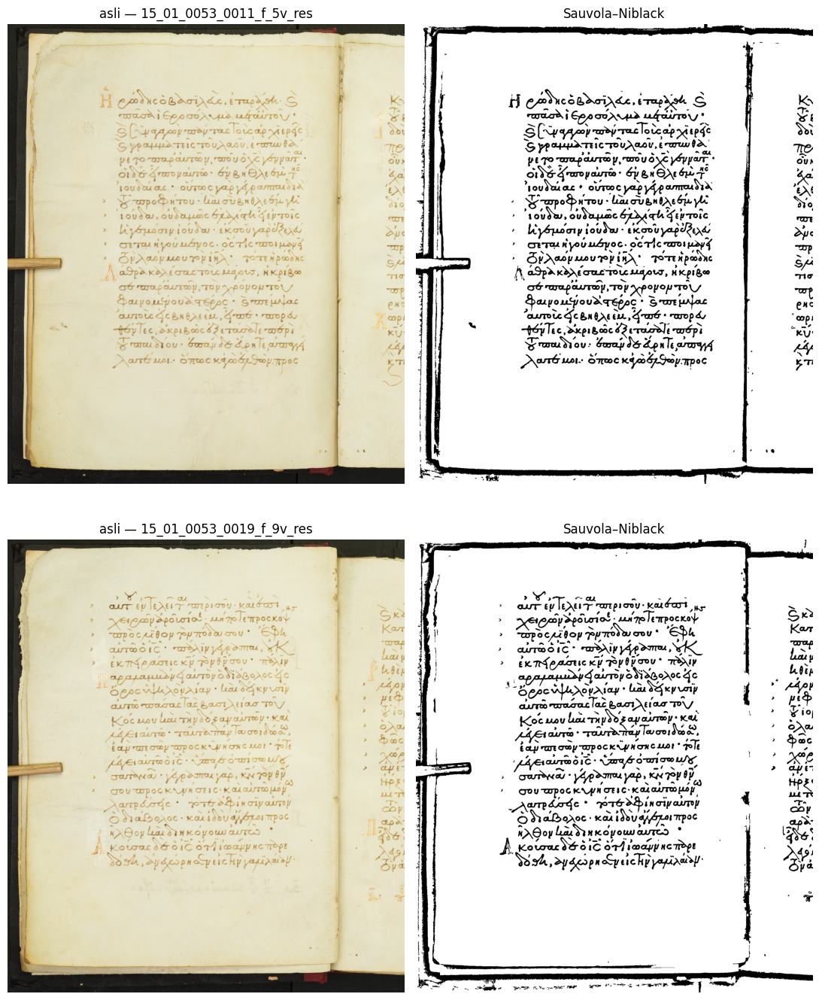

In [8]:
# >>>>>> [TAMBAHAN Sauvola–Niblack] — pratinjau sebelum/sesudah pada 2 gambar uji
import matplotlib.pyplot as plt
fig, axs = plt.subplots(2, 2, figsize=(11, 14))
for r, ((n, ip, _), (_, sp, _)) in enumerate(zip(pairs[:2], pairs_sn[:2])):
    axs[r, 0].imshow(cv2.cvtColor(cv2.imread(ip), cv2.COLOR_BGR2RGB)); axs[r, 0].set_title(f"asli — {n}")
    axs[r, 1].imshow(cv2.cvtColor(cv2.imread(sp), cv2.COLOR_BGR2RGB)); axs[r, 1].set_title("Sauvola–Niblack")
    for a in axs[r]: a.axis("off")
plt.tight_layout(); plt.show()
# <<<<<< [/TAMBAHAN]


## 4. Pasang kraken di virtual environment terpisah
Butuh beberapa menit (torch ikut terunduh). Dilewati otomatis bila venv sudah ada.

In [9]:
import subprocess, sys, shutil

VENV_PY = f"{VENV_DIR}/bin/python"

# Environment bersih: buang PYTHONPATH dll. dari Kaggle agar venv tidak memuat sitecustomize (pesan 'No module named wrapt')
CLEAN_ENV = {k: v for k, v in os.environ.items() if k not in ('PYTHONPATH', 'PYTHONSTARTUP', 'PYTHONHOME')}

def sh(cmd):
    print("$", cmd)
    subprocess.run(cmd, shell=True, check=True, env=CLEAN_ENV)

if not os.path.exists(VENV_PY):
    try:
        sh(f"{sys.executable} -m venv {VENV_DIR}")
    except subprocess.CalledProcessError:
        sh(f"{sys.executable} -m pip install -q virtualenv")
        shutil.rmtree(VENV_DIR, ignore_errors=True)
        sh(f"{sys.executable} -m virtualenv {VENV_DIR}")
    sh(f"{VENV_PY} -m pip install -q --no-cache-dir -U pip")
    sh(f"{VENV_PY} -m pip install -q --no-cache-dir 'kraken>=7.1.0' huggingface_hub pillow")
else:
    print("venv sudah ada, dilewati:", VENV_DIR)

sh(f"{VENV_PY} -m pip list 2>/dev/null | grep -i -E '^(kraken|torch|safetensors|transformers) '")

# Cek apakah GPU benar-benar bisa dipakai di venv (GPU lama mis. P100 bisa tidak didukung torch terbaru) -> fallback ke CPU
r = subprocess.run([VENV_PY, "-c", "import torch; x=torch.zeros(1).cuda(); print(float((x+1).item()))"],
                   capture_output=True, text=True, env=CLEAN_ENV)
USE_GPU = (r.returncode == 0)
print("GPU dipakai:", USE_GPU, "" if USE_GPU else "(fallback ke CPU)")
if not USE_GPU:
    print("Alasan (baris terakhir):", (r.stderr.strip().splitlines() or ["tidak ada pesan"])[-1])

$ /usr/bin/python3 -m venv /tmp/kraken_env
$ /usr/bin/python3 -m pip install -q virtualenv


Error: Command '['/tmp/kraken_env/bin/python3', '-m', 'ensurepip', '--upgrade', '--default-pip']' returned non-zero exit status 1.


$ /usr/bin/python3 -m virtualenv /tmp/kraken_env
created virtual environment CPython3.13.15.final.0-64-x86_64 in 500ms
  creator CPython3Posix(dest=/tmp/kraken_env, clear=False, no_vcs_ignore=False, venv_redirect=None, global=False)
  seeder FromAppData(download=False, pip=bundle, via=copy, app_data_dir=/root/.cache/virtualenv)
    added seed packages: pip==26.3
  activators BashActivator,CShellActivator,FishActivator,NushellActivator,PowerShellActivator,PythonActivator,XonshActivator
$ /tmp/kraken_env/bin/python -m pip install -q --no-cache-dir -U pip


Error in sitecustomize; set PYTHONVERBOSE for traceback:
ModuleNotFoundError: No module named 'wrapt'


$ /tmp/kraken_env/bin/python -m pip install -q --no-cache-dir 'kraken>=7.1.0' huggingface_hub pillow


Error in sitecustomize; set PYTHONVERBOSE for traceback:
ModuleNotFoundError: No module named 'wrapt'


$ /tmp/kraken_env/bin/python -m pip list 2>/dev/null | grep -i -E '^(kraken|torch|safetensors|transformers) '
kraken                    7.2
safetensors               0.7.0
torch                     2.14.0
GPU dipakai: False (fallback ke CPU)
Alasan (baris terakhir): RuntimeError: Found no NVIDIA driver on your system. Please check that you have an NVIDIA GPU and installed a driver from http://www.nvidia.com/Download/index.aspx


## 5. Jalankan segmentasi (di venv) → simpan prediksi baris ke JSON
Fungsi `run_segmentation()` bisa dipakai ulang untuk model base maupun model finetune (argumen `weights_path`).

In [10]:
import json

SEG_SCRIPT = r"""
import sys, json
from PIL import Image

model_path, pairs_json, out_json = sys.argv[1:4]
weights_path = sys.argv[4] if len(sys.argv) > 4 else None   # file .safetensors hasil finetune (opsional)
pairs = json.load(open(pairs_json))

from kraken.tasks import SegmentationTaskModel
from kraken.configs import SegmentationInferenceConfig


def _remap_keys(sd, target_keys):
    # Samakan nama key state_dict dengan nama key model kraken (buang/tambah prefix bila perlu).
    tset = set(target_keys)
    best, best_n = sd, len(tset & set(sd))
    for strip in (1, 2, 3):                                  # buang prefix: 'model.', 'module.', '<uuid>.', dst.
        cand = {".".join(k.split(".")[strip:]): v for k, v in sd.items()}
        n = len(tset & set(cand))
        if n > best_n:
            best, best_n = cand, n
    first = next(iter(sd))                                   # tambah prefix: mis. weights disimpan dari net.nn saja
    for pref in {k[:-len(first)] for k in tset if k.endswith(first) and len(k) > len(first)}:
        cand = {pref + k: v for k, v in sd.items()}
        n = len(tset & set(cand))
        if n > best_n:
            best, best_n = cand, n
    return best


def load_task(model_path, weights_path):
    if weights_path is None:
        return SegmentationTaskModel.load_model(model_path)
    from safetensors import safe_open
    from safetensors.torch import load_file
    with safe_open(weights_path, framework="pt") as f:
        meta = f.metadata() or {}
    if "kraken_meta" in meta:
        # Cara A: .safetensors lengkap (arsitektur + bobot), mis. hasil `ketos segtrain` / `ketos convert`.
        print("[LOAD] safetensors punya metadata kraken -> dimuat langsung", flush=True)
        return SegmentationTaskModel.load_model(weights_path)
    # Cara B: .safetensors hanya berisi bobot (state_dict) -> pasang ke arsitektur model base.
    print("[LOAD] safetensors hanya bobot -> dipasang ke arsitektur model base", flush=True)
    task = SegmentationTaskModel.load_model(model_path)
    net = task.seg_models[0]
    sd = _remap_keys(load_file(weights_path), net.state_dict().keys())
    res = net.load_state_dict(sd, strict=False)
    if res.missing_keys or res.unexpected_keys:
        raise RuntimeError(f"Bobot tidak cocok dengan model base.\nMissing ({len(res.missing_keys)}): "
                           f"{res.missing_keys[:5]}\nUnexpected ({len(res.unexpected_keys)}): {res.unexpected_keys[:5]}")
    print(f"[LOAD] {len(sd)} tensor berhasil dimuat", flush=True)
    return task


model = load_task(model_path, weights_path)
cfg = SegmentationInferenceConfig()


def pts(b):
    return [[float(x), float(y)] for x, y in b]


out = {}
for k, (name, ipath) in enumerate(pairs, 1):
    im = Image.open(ipath).convert("RGB")
    try:
        seg = model.predict(im, cfg)
    except Exception as e:
        print("[SKIP]", name, e, flush=True)
        continue
    lines = [pts(l.boundary) for l in seg.lines if getattr(l, "boundary", None) is not None and len(l.boundary) >= 3]
    out[name] = {"size": list(im.size), "line": lines}      # region sengaja tidak disimpan (fokus line segmentation)
    print(f"[{k}/{len(pairs)}] {name}: {len(lines)} baris", flush=True)

json.dump(out, open(out_json, "w"))
print("DONE", flush=True)
"""
with open("/tmp/seg_script.py", "w") as f:
    f.write(SEG_SCRIPT)


def run_segmentation(pred_json, weights_path=None, reuse=True, pairs_override=None):   # >>>>>> [TAMBAHAN Sauvola–Niblack]: parameter pairs_override # <<<<<< [/TAMBAHAN]
    """Jalankan segmentasi di venv kraken dan simpan hasil baris ke pred_json.
    weights_path=None -> model base; isi path .safetensors -> model finetune."""
    # >>>>>> [TAMBAHAN Sauvola–Niblack] — pakai gambar hasil preprocessing bila pairs_override diberikan
    use_pairs = pairs_override if pairs_override is not None else pairs
    # <<<<<< [/TAMBAHAN]
    need = {n for n, _, _ in use_pairs}
    if reuse and os.path.exists(pred_json):
        if need.issubset(set(json.load(open(pred_json)).keys())):
            print("Cache prediksi lengkap, dipakai ulang:", pred_json)
            return pred_json
    with open("/tmp/pairs.json", "w") as f:
        json.dump([[n, ip] for n, ip, _ in use_pairs], f)
    env = dict(CLEAN_ENV)
    if not USE_GPU:
        env["CUDA_VISIBLE_DEVICES"] = ""
    cmd = [VENV_PY, "-u", "/tmp/seg_script.py", model_path, "/tmp/pairs.json", pred_json]
    if weights_path:
        cmd.append(weights_path)
    proc = subprocess.Popen(cmd, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, env=env)
    for line in proc.stdout:
        print(line, end="")
    if proc.wait() != 0:
        raise RuntimeError("Segmentasi gagal, lihat log di atas.")
    print("Prediksi tersimpan:", pred_json)
    return pred_json


# Model BASE
run_segmentation(PRED_JSON, weights_path=None, reuse=REUSE_PREDICTIONS)

Error in sitecustomize; set PYTHONVERBOSE for traceback:
ModuleNotFoundError: No module named 'wrapt'
[1/27] 15_01_0053_0011_f_5v_res: 20 baris
[2/27] 15_01_0053_0019_f_9v_res: 19 baris
[3/27] 15_01_0053_0025_f_12v_res: 21 baris
[4/27] 15_01_0053_0038_f_19r_res: 20 baris
[5/27] 15_01_0053_0054_f_27r_res: 20 baris
[6/27] 15_01_0053_0055_f_27v_res: 22 baris
[7/27] 15_01_0079_0052_f_7r_res: 25 baris
[8/27] 15_01_0079_0056_f_9r_res: 23 baris
[9/27] 15_01_0079_0059_f_10v_res: 21 baris
[10/27] 15_01_0079_0067_f_14v_res: 20 baris
[11/27] 15_01_0114_0018_f_5r_res: 25 baris
[12/27] 15_01_0114_0022_f_7r_res: 24 baris
[13/27] 15_01_0114_0034_f_13r_res: 26 baris
[14/27] 15_01_0114_0047_f_19v_res: 23 baris
[15/27] 15_01_0114_0050_f_21r_res: 26 baris
[16/27] 6791 (13): 25 baris
[17/27] 6791 (2): 22 baris
[18/27] 6791 (42): 26 baris
[19/27] 6791 (46): 20 baris
[20/27] 6791 (5): 23 baris
[21/27] 6791 (50): 23 baris
[22/27] 6791 (52): 23 baris
[23/27] 6791 (66): 29 baris
Polygonizer failed on line 0: T

'/kaggle/working/predictions_raw.json'

## 6. Bangun matriks IoU per halaman (prediksi vs ground truth)

In [11]:
from tqdm.auto import tqdm

def iou_matrix(preds, gts):
    M = np.zeros((len(preds), len(gts)), dtype=np.float64)
    for i, p in enumerate(preds):
        for j, g in enumerate(gts):
            if p.bounds[2] < g.bounds[0] or g.bounds[2] < p.bounds[0] or p.bounds[3] < g.bounds[1] or g.bounds[3] < p.bounds[1]:
                continue
            inter = p.intersection(g).area
            if inter > 0:
                M[i, j] = inter / (p.area + g.area - inter)
    return M

def area_iou(preds, gts):
    if not preds and not gts:
        return 1.0
    if not preds or not gts:
        return 0.0
    Pu, Gu = unary_union(preds), unary_union(gts)
    u = Pu.union(Gu).area
    return Pu.intersection(Gu).area / u if u > 0 else 0.0

def build_records(pred_json):
    # Bangun matriks IoU per halaman dari file prediksi (bisa dipakai untuk model base maupun finetune).
    raw = json.load(open(pred_json))
    recs = {lv: [] for lv in LEVELS}
    for name, ipath, xpath in tqdm(pairs, desc="Hitung IoU"):
        if name not in raw:
            print("[SKIP] tidak ada prediksi:", name)
            continue
        pr = raw[name]
        gt = load_gt(xpath, tuple(pr["size"]))
        for lv in LEVELS:
            preds = [p for p in (to_poly(b) for b in pr[lv]) if p is not None]
            gts = gt[lv]
            recs[lv].append({
                "name": name,
                "iou": iou_matrix(preds, gts),
                # kraken tidak mengeluarkan confidence per-objek -> semua prediksi diberi skor 1.0
                "scores": np.ones(len(preds)),
                "n_pred": len(preds), "n_gt": len(gts),
                "area_iou": area_iou(preds, gts),
                "preds": preds, "gts": gts, "size": tuple(pr["size"]), "path": ipath,
            })
    return recs

records = build_records(PRED_JSON)          # model BASE
print("Selesai:", {lv: len(v) for lv, v in records.items()}, "halaman")

Hitung IoU:   0%|          | 0/27 [00:00<?, ?it/s]

Selesai: {'line': 27} halaman


## 7. Fungsi metrik (IoU, P/R/F1, AP, mAP, mAP.50, mAP.50:95)

In [12]:
import pandas as pd

def match_image(iou, scores, thr):
    # Greedy matching ala COCO: prediksi diurut skor (tie-break: IoU terbesar), tiap prediksi ambil GT bebas ber-IoU tertinggi >= thr.
    n_pred, n_gt = iou.shape
    tp = np.zeros(n_pred, dtype=bool)
    matched_ious = []
    if n_pred == 0 or n_gt == 0:
        return tp, matched_ious
    best = iou.max(axis=1)
    order = np.lexsort((-best, -scores))
    taken = np.zeros(n_gt, dtype=bool)
    for i in order:
        cand = np.where(~taken, iou[i], -1.0)
        j = int(cand.argmax())
        if cand[j] >= thr and cand[j] > 0:
            tp[i] = True
            taken[j] = True
            matched_ious.append(float(iou[i, j]))
    return tp, matched_ious

def compute_ap(scores, tps, n_gt):
    # AP 101-titik (COCO) untuk satu kelas.
    if n_gt == 0:
        return float("nan")
    if len(scores) == 0:
        return 0.0
    order = np.argsort(-np.asarray(scores), kind="stable")
    tp = np.asarray(tps, dtype=float)[order]
    fp = 1.0 - tp
    ctp, cfp = np.cumsum(tp), np.cumsum(fp)
    rec = ctp / n_gt
    prec = ctp / np.maximum(ctp + cfp, 1e-12)
    for k in range(len(prec) - 2, -1, -1):          # precision envelope
        prec[k] = max(prec[k], prec[k + 1])
    rec_th = np.linspace(0, 1, 101)
    idx = np.searchsorted(rec, rec_th, side="left")
    q = np.array([prec[i] if i < len(prec) else 0.0 for i in idx])
    return float(q.mean())

def evaluate_level(recs, thresholds):
    n_gt = sum(r["n_gt"] for r in recs)
    n_pred = sum(r["n_pred"] for r in recs)
    per_thr = []
    for t in thresholds:
        all_s, all_tp, tp_total, mious = [], [], 0, []
        for r in recs:
            tp, mi = match_image(r["iou"], r["scores"], t)
            all_s.extend(r["scores"].tolist()); all_tp.extend(tp.tolist())
            tp_total += int(tp.sum()); mious += mi
        fp, fn = n_pred - tp_total, n_gt - tp_total
        P = tp_total / (tp_total + fp) if (tp_total + fp) else 0.0
        R = tp_total / (tp_total + fn) if (tp_total + fn) else 0.0
        F1 = 2 * P * R / (P + R) if (P + R) else 0.0
        ap = compute_ap(all_s, all_tp, n_gt)
        per_thr.append({"IoU_thr": float(t), "TP": tp_total, "FP": fp, "FN": fn,
                        "Precision": P, "Recall": R, "F1": F1, "AP": ap,
                        "mean_IoU_matched": float(np.mean(mious)) if mious else 0.0})
    per_thr = pd.DataFrame(per_thr)

    thr = per_thr.IoU_thr.values
    m50   = np.isclose(thr, MAP50_THR)
    m5095 = (thr >= MAP5095_RANGE[0] - 1e-9) & (thr <= MAP5095_RANGE[1] + 1e-9)

    # IoU terbaik tiap GT (GT yang tak terdeteksi dihitung 0) -> tidak bergantung ambang
    best_gt = np.concatenate([r["iou"].max(axis=0) if r["iou"].shape[0] else np.zeros(r["n_gt"]) for r in recs]) if n_gt else np.array([0.0])
    summary = {
        "Halaman": len(recs), "GT": n_gt, "Prediksi": n_pred,
        # rata-rata di seluruh ambang IoU (tanpa basis 0.5)
        "Precision": float(per_thr.Precision.mean()),
        "Recall":    float(per_thr.Recall.mean()),
        "F1":        float(per_thr.F1.mean()),
        "mAP":       float(np.nanmean(per_thr.AP.values)),                 # rata-rata AP, IoU 0.05:0.95
        "mAP.50":    float(per_thr.loc[m50, "AP"].iloc[0]),                # AP pada IoU 0.50
        "mAP.50:95": float(np.nanmean(per_thr.loc[m5095, "AP"].values)),   # rata-rata AP, IoU 0.50:0.95
        "Mean IoU (best-IoU per GT)": float(best_gt.mean()),
        "Mean IoU area per halaman": float(np.mean([r["area_iou"] for r in recs])),
    }
    return summary, per_thr


## 8. Hasil evaluasi

In [13]:
import json
all_summary = {}
for lv in LEVELS:
    if not records[lv]:
        continue
    summary, per_thr = evaluate_level(records[lv], IOU_THRESHOLDS)
    all_summary[lv] = summary
    print(f"\n================ LEVEL: {lv.upper()} ================")
    display(pd.Series(summary, name=lv).to_frame())
    display(per_thr.round(4))
    per_thr.to_csv(f"{WORK_DIR}/metrics_per_threshold_{lv}.csv", index=False)

summary_df = pd.DataFrame(all_summary).T
display(summary_df.round(4))
summary_df.to_csv(f"{WORK_DIR}/metrics_summary.csv")
with open(f"{WORK_DIR}/metrics_summary.json", "w") as f:
    json.dump(all_summary, f, indent=2)
print("Tersimpan di", WORK_DIR)


================ LEVEL: LINE ================


,line
Halaman,27.000000
GT,537.000000
Prediksi,619.000000
Precision,0.585835
Recall,0.675292
F1,0.627390
mAP,0.579345
mAP.50,0.847823
mAP.50:95,0.287835
Mean IoU (best-IoU per GT),0.665803


,IoU_thr,TP,FP,FN,Precision,Recall,F1,AP,mean_IoU_matched
0,0.05,536,83,1,0.8659,0.9981,0.9273,0.9096,0.6670
1,0.10,536,83,1,0.8659,0.9981,0.9273,0.9096,0.6670
2,0.15,536,83,1,0.8659,0.9981,0.9273,0.9096,0.6670
3,0.20,535,84,2,0.8643,0.9963,0.9256,0.9095,0.6680
4,0.25,535,84,2,0.8643,0.9963,0.9256,0.9095,0.6680
5,0.30,534,85,3,0.8627,0.9944,0.9239,0.9093,0.6688
6,0.35,530,89,7,0.8562,0.9870,0.9170,0.8986,0.6714
7,0.40,527,92,10,0.8514,0.9814,0.9118,0.8979,0.6730
8,0.45,518,101,19,0.8368,0.9646,0.8962,0.8757,0.6774
9,0.50,508,111,29,0.8207,0.9460,0.8789,0.8478,0.6814


,Halaman,GT,Prediksi,Precision,Recall,F1,mAP,mAP.50,mAP.50:95,Mean IoU (best-IoU per GT),Mean IoU area per halaman
line,27.0,537.0,619.0,0.5858,0.6753,0.6274,0.5793,0.8478,0.2878,0.6658,0.696


Tersimpan di /kaggle/working


## 9. Hasil per halaman (opsional)

In [14]:
for lv in LEVELS:
    rows = []
    for r in records[lv]:
        Ps, Rs, F1s = [], [], []
        for t in IOU_THRESHOLDS:
            tp, _ = match_image(r["iou"], r["scores"], t)
            TP = int(tp.sum()); FP = r["n_pred"] - TP; FN = r["n_gt"] - TP
            P = TP / (TP + FP) if TP + FP else 0.0
            R = TP / (TP + FN) if TP + FN else 0.0
            Ps.append(P); Rs.append(R); F1s.append(2*P*R/(P+R) if P+R else 0.0)
        rows.append({"halaman": r["name"], "GT": r["n_gt"], "Pred": r["n_pred"],
                     "Precision": np.mean(Ps), "Recall": np.mean(Rs), "F1": np.mean(F1s),   # rata-rata semua ambang IoU
                     "IoU_area": r["area_iou"]})
    df = pd.DataFrame(rows)
    df.to_csv(f"{WORK_DIR}/per_page_{lv}.csv", index=False)
    print(f"--- {lv}: 10 halaman dengan F1 terendah ---")
    display(df.sort_values("F1").head(10).round(3))

--- line: 10 halaman dengan F1 terendah ---


,halaman,GT,Pred,Precision,Recall,F1,IoU_area
24,6971 (113),19,26,0.387,0.529,0.447,0.563
22,6791 (66),19,29,0.416,0.634,0.502,0.646
25,6971 (87),19,22,0.498,0.576,0.534,0.605
26,6971 (89),19,23,0.499,0.604,0.546,0.604
15,6791 (13),19,25,0.493,0.648,0.560,0.662
7,15_01_0079_0056_f_9r_res,20,23,0.542,0.624,0.580,0.674
21,6791 (52),19,23,0.533,0.645,0.584,0.656
17,6791 (42),19,26,0.510,0.698,0.589,0.690
2,15_01_0053_0025_f_12v_res,19,21,0.564,0.623,0.592,0.702
20,6791 (50),19,23,0.568,0.687,0.622,0.691


## 10. Visualisasi (hijau = ground truth, merah = prediksi)

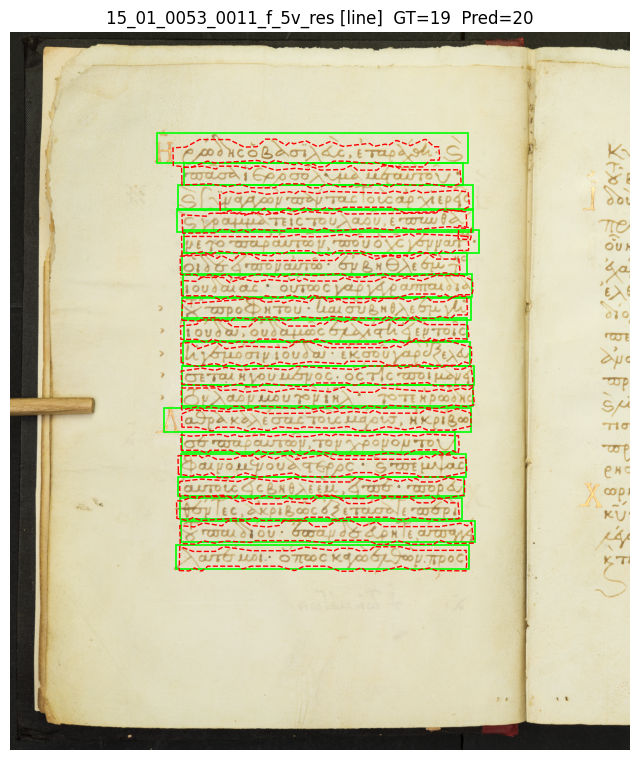

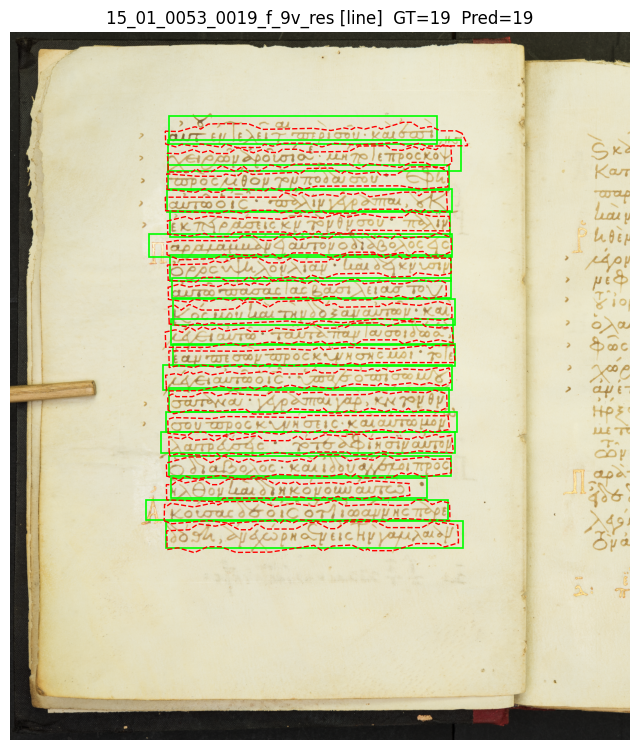

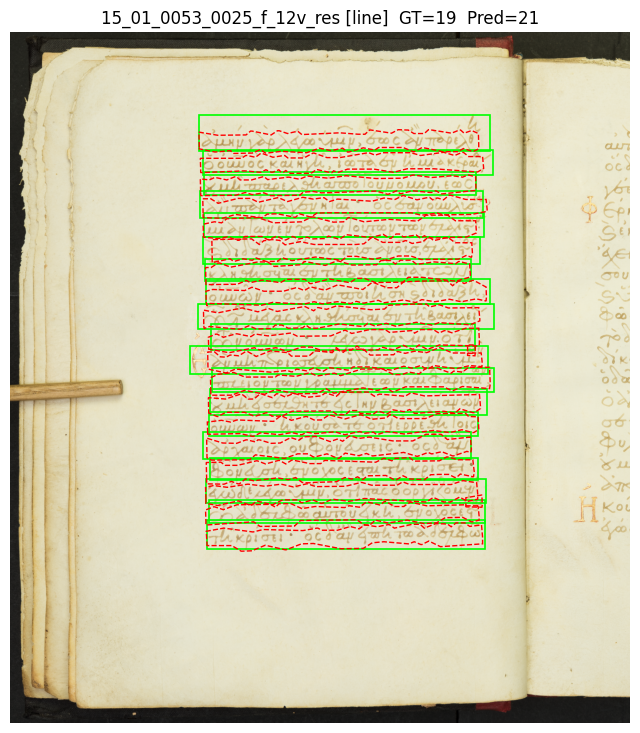

In [15]:
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon as MplPoly

VIS_LEVEL, N_VIS = LEVELS[0], 3
for r in records[VIS_LEVEL][:N_VIS]:
    im = Image.open(r["path"]).convert("RGB")
    fig, ax = plt.subplots(figsize=(8, 10))
    ax.imshow(im)
    for g in r["gts"]:
        ax.add_patch(MplPoly(np.array(g.exterior.coords), fill=False, ec="lime", lw=1.2))
    for p in r["preds"]:
        ax.add_patch(MplPoly(np.array(p.exterior.coords), fill=False, ec="red", lw=1.0, ls="--"))
    ax.set_title(f"{r['name']} [{VIS_LEVEL}]  GT={r['n_gt']}  Pred={r['n_pred']}")
    ax.axis("off")
    plt.show()

# Finetune 1: Full finetune no freeze
Cell di bawah memasang `bll_finetune_best.safetensors` ke model kraken, menjalankan segmentasi, lalu membandingkannya dengan model base (line segmentation).

In [16]:
# Lokasi file bobot hasil finetune.
# Kaggle: upload file sebagai Dataset (atau taruh di /kaggle/working), lalu isi path-nya di FT1_WEIGHTS.
# Jika dibiarkan None, notebook mencarinya otomatis berdasarkan nama file.
FT1_NAME    = "blla_finetuned_freeze_encoder_best.safetensors"
FT1_WEIGHTS = "/kaggle/input/notebooks/gracians/kraken-blla-finetune-freeze-encoder/blla_finetuned_freeze_encoder_best.safetensors"          # contoh: "/kaggle/input/nama-dataset-kamu/bll_finetune_best.safetensors"

if FT1_WEIGHTS is None:
    hits = (glob.glob(f"/kaggle/input/**/{FT1_NAME}", recursive=True)
            + glob.glob(f"{WORK_DIR}/**/{FT1_NAME}", recursive=True))
    if not hits:
        raise FileNotFoundError(f"{FT1_NAME} tidak ditemukan. Upload sebagai Kaggle Dataset lalu isi FT1_WEIGHTS manual.")
    FT1_WEIGHTS = hits[0]
print("Bobot finetune 1:", FT1_WEIGHTS)
print("Arsitektur dasar :", model_path)    # .mlmodel base dari bagian 2, dipakai bila safetensors hanya berisi bobot

Bobot finetune 1: /kaggle/input/notebooks/gracians/kraken-blla-finetune-freeze-encoder/blla_finetuned_freeze_encoder_best.safetensors
Arsitektur dasar : /kaggle/working/kraken-blla-base/blla.mlmodel


In [ ]:
# 1) Segmentasi dengan model finetune (prediksi disimpan terpisah dari model base!)
FT1_PRED_JSON = f"{WORK_DIR}/predictions_ft1.json"
run_segmentation(FT1_PRED_JSON, weights_path=FT1_WEIGHTS, reuse=REUSE_PREDICTIONS)

# 2) Hitung IoU + metrik (level line)
records_ft1 = build_records(FT1_PRED_JSON)
summary_ft1, per_thr_ft1 = evaluate_level(records_ft1["line"], IOU_THRESHOLDS)
per_thr_ft1.to_csv(f"{WORK_DIR}/metrics_per_threshold_line_ft1.csv", index=False)

# 3) Perbandingan base vs finetune 1
summary_base = all_summary["line"] if "all_summary" in globals() and "line" in all_summary \
    else evaluate_level(records["line"], IOU_THRESHOLDS)[0]
cmp_df = pd.DataFrame({"Base": summary_base, "Finetune 1": summary_ft1}).T
cmp_df.loc["Selisih (FT1 - Base)"] = cmp_df.loc["Finetune 1"] - cmp_df.loc["Base"]
display(cmp_df.round(4))
cmp_df.to_csv(f"{WORK_DIR}/comparison_base_vs_ft1.csv")

Error in sitecustomize; set PYTHONVERBOSE for traceback:
ModuleNotFoundError: No module named 'wrapt'
[LOAD] safetensors punya metadata kraken -> dimuat langsung
[1/27] 15_01_0053_0011_f_5v_res: 19 baris
[2/27] 15_01_0053_0019_f_9v_res: 19 baris
[3/27] 15_01_0053_0025_f_12v_res: 19 baris
[4/27] 15_01_0053_0038_f_19r_res: 19 baris
[5/27] 15_01_0053_0054_f_27r_res: 19 baris
[6/27] 15_01_0053_0055_f_27v_res: 19 baris
[7/27] 15_01_0079_0052_f_7r_res: 21 baris
[8/27] 15_01_0079_0056_f_9r_res: 20 baris
[9/27] 15_01_0079_0059_f_10v_res: 20 baris
[10/27] 15_01_0079_0067_f_14v_res: 20 baris
[11/27] 15_01_0114_0018_f_5r_res: 23 baris
[12/27] 15_01_0114_0022_f_7r_res: 23 baris
[13/27] 15_01_0114_0034_f_13r_res: 23 baris
[14/27] 15_01_0114_0047_f_19v_res: 23 baris
[15/27] 15_01_0114_0050_f_21r_res: 23 baris
[16/27] 6791 (13): 19 baris
[17/27] 6791 (2): 19 baris
[18/27] 6791 (42): 20 baris


# Finetune 2: Finetune with freezing encoder

In [ ]:
# Lokasi file bobot hasil finetune.
# Kaggle: upload file sebagai Dataset (atau taruh di /kaggle/working), lalu isi path-nya di FT1_WEIGHTS.
# Jika dibiarkan None, notebook mencarinya otomatis berdasarkan nama file.
FT2_NAME    = "blla-finetune-freeze-encoder_best.safetensors"
FT2_WEIGHTS = "/kaggle/input/notebooks/gracians/kraken-blla-training/blla_finetuned_best.safetensors"          # contoh: "/kaggle/input/nama-dataset-kamu/bll_finetune_best.safetensors"

if FT2_WEIGHTS is None:
    hits = (glob.glob(f"/kaggle/input/**/{FT2_NAME}", recursive=True)
            + glob.glob(f"{WORK_DIR}/**/{FT2_NAME}", recursive=True))
    if not hits:
        raise FileNotFoundError(f"{FT2_NAME} tidak ditemukan. Upload sebagai Kaggle Dataset lalu isi FT2_WEIGHTS manual.")
    FT2_WEIGHTS = hits[0]
print("Bobot finetune 2:", FT2_WEIGHTS)
print("Arsitektur dasar :", model_path)    # .mlmodel base dari bagian 2, dipakai bila safetensors hanya berisi bobot

In [19]:
# 1) Segmentasi dengan model finetune (prediksi disimpan terpisah dari model base!)
FT2_PRED_JSON = f"{WORK_DIR}/predictions_ft2.json"
run_segmentation(FT2_PRED_JSON, weights_path=FT2_WEIGHTS, reuse=REUSE_PREDICTIONS)

# 2) Hitung IoU + metrik (level line)
records_ft2 = build_records(FT2_PRED_JSON)
summary_ft2, per_thr_ft2 = evaluate_level(records_ft2["line"], IOU_THRESHOLDS)
per_thr_ft2.to_csv(f"{WORK_DIR}/metrics_per_threshold_line_ft2.csv", index=False)

# 3) Perbandingan base vs finetune 1
summary_base = all_summary["line"] if "all_summary" in globals() and "line" in all_summary \
    else evaluate_level(records["line"], IOU_THRESHOLDS)[0]
cmp_df = pd.DataFrame({"Base": summary_base, "Finetune Freeze All":summary_ft1, "Finetune Freeze Encoder": summary_ft2}).T
display(cmp_df.round(3))
cmp_df.to_csv(f"{WORK_DIR}/comparison_base_vs_ft1.csv")

[10/27] 15_01_0079_0067_f_14v_res: 20 baris
[11/27] 15_01_0114_0018_f_5r_res: 23 baris
[12/27] 15_01_0114_0022_f_7r_res: 22 baris
[13/27] 15_01_0114_0034_f_13r_res: 23 baris
[14/27] 15_01_0114_0047_f_19v_res: 23 baris
[15/27] 15_01_0114_0050_f_21r_res: 23 baris
[16/27] 6791 (13): 19 baris
[17/27] 6791 (2): 20 baris
[18/27] 6791 (42): 19 baris
[19/27] 6791 (46): 19 baris
[20/27] 6791 (5): 21 baris
[21/27] 6791 (50): 21 baris
[22/27] 6791 (52): 19 baris
[23/27] 6791 (66): 21 baris
[24/27] 6791 (68): 20 baris
[25/27] 6971 (113): 18 baris
[26/27] 6971 (87): 21 baris
[27/27] 6971 (89): 20 baris
DONE
Prediksi tersimpan: /kaggle/working/predictions_ft2.json


Hitung IoU:   0%|          | 0/27 [00:00<?, ?it/s]

,Halaman,GT,Prediksi,Precision,Recall,F1,mAP,mAP.50,mAP.50:95,Mean IoU (best-IoU per GT),Mean IoU area per halaman
Base,27.0,537.0,619.0,0.586,0.675,0.627,0.579,0.848,0.288,0.666,0.696
Finetune Freeze All,27.0,537.0,544.0,0.682,0.690,0.686,0.647,0.957,0.344,0.681,0.706
Finetune Freeze Encoder,27.0,537.0,548.0,0.676,0.690,0.683,0.644,0.958,0.338,0.681,0.708


# Komparasi Visualisasi

In [20]:
# Base
records_base = records

# Finetune Freeze All
records_ft1 = build_records(FT1_PRED_JSON)

# Finetune Freeze Encoder
records_ft2 = build_records(FT2_PRED_JSON)

Hitung IoU:   0%|          | 0/27 [00:00<?, ?it/s]

Hitung IoU:   0%|          | 0/27 [00:00<?, ?it/s]

In [21]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Polygon as MplPoly
from PIL import Image

def visualize_comparison(
    records_base,
    records_ft1,
    records_ft2,
    level="line",
    n_vis=3
):
    # Ambil records dari setiap model
    datasets = {
        "Base Model": records_base[level],
        "Finetune All": records_ft1[level],
        "Finetune Freeze Encoder": records_ft2[level]
    }

    # Cocokkan gambar berdasarkan nama file
    indexes = {
        model: {r["name"]: r for r in data}
        for model, data in datasets.items()
    }

    base_data = datasets["Base Model"]

    for base_r in base_data[:n_vis]:
        name = base_r["name"]

        # Pastikan gambar tersedia di semua model
        if not all(name in indexes[m] for m in datasets):
            print(f"Data tidak lengkap: {name}")
            continue

        fig, axes = plt.subplots(
            1, 5,                 # >>>>>> [PERBAIKAN]: 1 panel GT + 4 model (sebelumnya 4 panel -> model SN tidak tampil) # <<<<<< [/PERBAIKAN]
            figsize=(30, 10)
        )

        # Ambil gambar asli
        im = Image.open(base_r["path"]).convert("RGB")

        # Panel pertama: Ground Truth
        axes[0].imshow(im)

        for g in base_r["gts"]:
            axes[0].add_patch(
                MplPoly(
                    np.array(g.exterior.coords),
                    fill=False,
                    ec="lime",
                    lw=1.3
                )
            )

        axes[0].set_title(
            f"Ground Truth\nGT={base_r['n_gt']}"
        )

        # Panel prediksi masing-masing model
        colors = {
            "Base Model": "#BF00FF",
            "Finetune All": "#00BFFF",                      # >>>>>> [PERBAIKAN]: kunci disamakan dengan nama di `datasets` (sebelumnya KeyError) # <<<<<< [/PERBAIKAN]
            "Finetune Freeze Encoder": "#FF1493",
        }

        for ax, (model, data) in zip(
            axes[1:],
            datasets.items()
        ):
            r = indexes[model][name]

            ax.imshow(im)

            # Ground Truth: hijau
            for g in r["gts"]:
                ax.add_patch(
                    MplPoly(
                        np.array(g.exterior.coords),
                        fill=False,
                        ec="lime",
                        lw=1.3
                    )
                )

            # Prediction: warna sesuai model
            for p in r["preds"]:
                ax.add_patch(
                    MplPoly(
                        np.array(p.exterior.coords),
                        fill=False,
                        ec=colors[model],
                        lw=1.1,
                        ls="--"
                    )
                )

            ax.set_title(
                f"{model}\n"
                f"GT={r['n_gt']} | Pred={r['n_pred']}"
            )

        for ax in axes:
            ax.axis("off")

        fig.suptitle(
            f"{name} [{level}]",
            fontsize=14,
            fontweight="bold"
        )

        plt.tight_layout()
        plt.show()

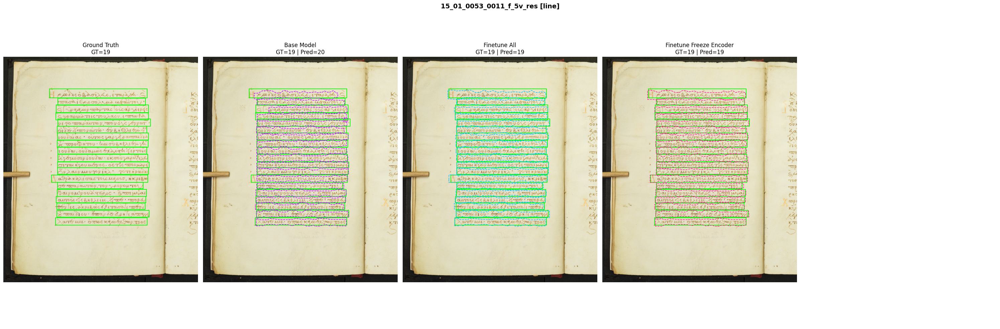

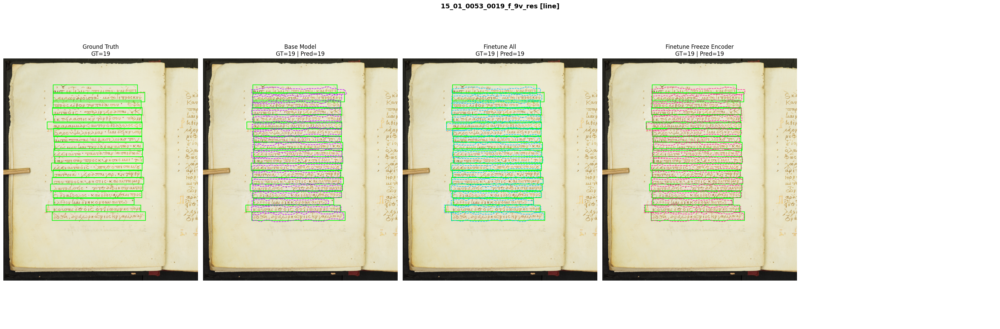

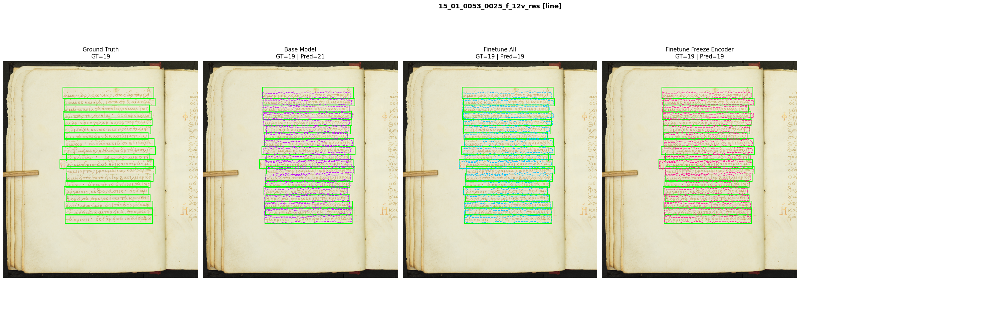

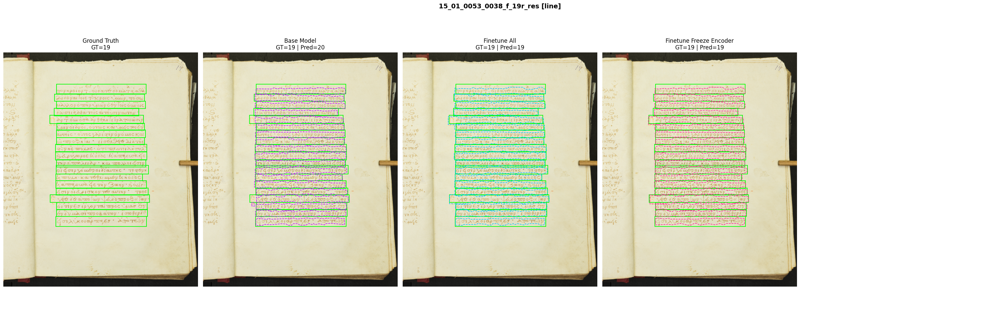

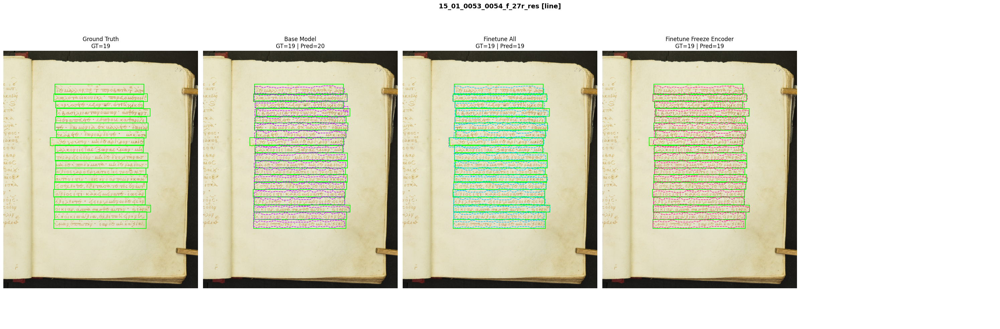

In [22]:
visualize_comparison(
    records_base=records_base,
    records_ft1=records_ft1,
    records_ft2=records_ft2,
    level="line",
    n_vis=5
)